# 2. Results

All models on the same test period. Differences smaller than the bootstrap interval or the range over seeds are not claims; three seeds give a range, not a confidence interval.

In [1]:
%matplotlib inline
from pipeline.notebook_support import *
import pandas as pd
import numpy as np
pd.set_option('display.width', 160)
fraud = load_results('results_fraud.csv')
account = load_results('results_account.csv')
print('config hash:', fraud['config_hash'].unique())

config hash: <StringArray>
['0a4fb49dd420']
Length: 1, dtype: str


In [2]:
metrics = ['pr_auc', 'roc_auc', 'recall_at_fpr', 'cost', 'brier', 'ece']
seed_summary(fraud, metrics).round(3)

,model,pr_auc_mean,roc_auc_mean,recall_at_fpr_mean,cost_mean,brier_mean,ece_mean,pr_auc_min,roc_auc_min,recall_at_fpr_min,cost_min,brier_min,ece_min,pr_auc_max,roc_auc_max,recall_at_fpr_max,cost_max,brier_max,ece_max
0,fraud_only,0.351,0.839,0.308,149587.220,0.070,0.194,0.348,0.832,0.300,142001.487,0.068,0.190,0.355,0.847,0.319,159333.986,0.072,0.199
1,fraud_only_history,0.338,0.830,0.323,172197.761,0.072,0.194,0.330,0.825,0.315,167305.376,0.071,0.190,0.347,0.838,0.336,177641.270,0.074,0.197
2,graph_labels_tabular,0.520,0.914,0.460,117395.283,0.023,0.004,0.516,0.912,0.457,115979.533,0.023,0.004,0.524,0.916,0.463,119703.825,0.024,0.004
3,graph_shared_tabular,0.464,0.887,0.423,135126.542,0.025,0.005,0.457,0.882,0.416,132649.387,0.025,0.005,0.469,0.889,0.432,139356.595,0.025,0.006
4,history_stable_tabular,0.465,0.885,0.434,139487.131,0.025,0.005,0.456,0.881,0.428,129892.775,0.025,0.004,0.476,0.888,0.441,144652.160,0.025,0.005
5,history_tabular,0.446,0.884,0.415,136641.191,0.025,0.006,0.438,0.883,0.405,134936.842,0.025,0.005,0.452,0.886,0.426,138535.991,0.026,0.006
6,multitask,0.343,0.837,0.306,153915.310,0.074,0.205,0.332,0.831,0.288,144336.203,0.069,0.192,0.349,0.841,0.318,160077.669,0.077,0.212
7,multitask_history,0.318,0.830,0.304,156105.542,0.074,0.202,0.307,0.828,0.295,149431.762,0.073,0.201,0.326,0.832,0.310,162713.212,0.074,0.204
8,naive_tabular,0.462,0.889,0.425,134285.125,0.025,0.006,0.449,0.886,0.422,132499.877,0.025,0.006,0.469,0.891,0.429,137007.278,0.025,0.007
9,no_graph,0.335,0.819,0.302,172599.068,0.063,0.172,0.328,0.808,0.291,160299.950,0.059,0.161,0.344,0.827,0.318,180143.909,0.066,0.181


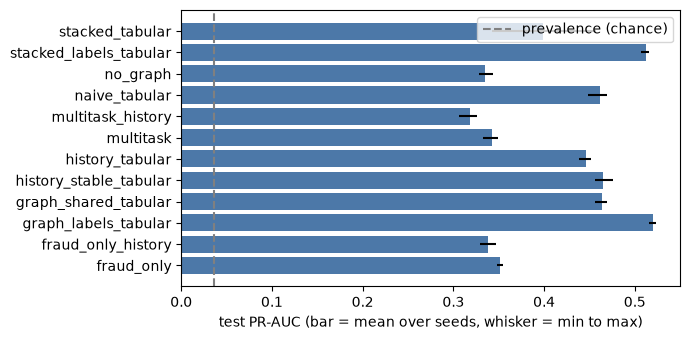

In [3]:
plot_pr_auc(fraud);

## Alert budgets

Recall, precision and the share of fraud *value* caught when only the top 0.5%, 1% or 5% of transactions can be reviewed.

In [4]:
cols = [c for c in fraud.columns if c.split('@')[0] in ('recall', 'precision', 'amount_recall') and '@' in c]
fraud.groupby('model')[cols].mean().round(3)

,recall@0.005,precision@0.005,amount_recall@0.005,recall@0.01,precision@0.01,amount_recall@0.01,recall@0.05,precision@0.05,amount_recall@0.05
model,,,,,,,,,
fraud_only,0.108,0.782,0.043,0.193,0.699,0.095,0.430,0.311,0.357
fraud_only_history,0.103,0.742,0.035,0.184,0.664,0.078,0.424,0.307,0.312
graph_labels_tabular,0.121,0.872,0.078,0.231,0.837,0.148,0.582,0.421,0.516
graph_shared_tabular,0.119,0.861,0.074,0.231,0.834,0.134,0.531,0.384,0.466
history_stable_tabular,0.119,0.858,0.075,0.230,0.831,0.131,0.531,0.384,0.455
history_tabular,0.116,0.841,0.073,0.228,0.823,0.128,0.521,0.377,0.441
multitask,0.110,0.794,0.037,0.197,0.712,0.080,0.405,0.293,0.331
multitask_history,0.113,0.817,0.040,0.192,0.696,0.072,0.379,0.274,0.282
naive_tabular,0.116,0.838,0.071,0.229,0.829,0.125,0.530,0.383,0.472


## Cost

Expected cost uses an assumed review cost per false alert (see the config); compare each model with flagging nothing.

In [5]:
fraud.groupby('model')[['cost', 'cost_flag_none', 'cost_flag_all']].mean().round(0)

,cost,cost_flag_none,cost_flag_all
model,,,
fraud_only,149587.0,370374.0,320990.0
fraud_only_history,172198.0,370374.0,320990.0
graph_labels_tabular,117395.0,370374.0,320990.0
graph_shared_tabular,135127.0,370374.0,320990.0
history_stable_tabular,139487.0,370374.0,320990.0
history_tabular,136641.0,370374.0,320990.0
multitask,153915.0,370374.0,320990.0
multitask_history,156106.0,370374.0,320990.0
naive_tabular,134285.0,370374.0,320990.0


## Account-risk head and ablations

In [6]:
seed_summary(account, ['pr_auc', 'roc_auc']).round(3)

,model,pr_auc_mean,roc_auc_mean,pr_auc_min,roc_auc_min,pr_auc_max,roc_auc_max
0,account_only,0.210,0.775,0.203,0.770,0.214,0.783
1,hgb_user_aggregates,0.133,0.675,0.116,0.659,0.151,0.683
2,mean_fraud_score,0.452,0.857,0.439,0.850,0.471,0.862
3,multitask,0.249,0.767,0.234,0.749,0.264,0.779
4,multitask_history,0.274,0.797,0.259,0.773,0.282,0.815


## Over time and calibration

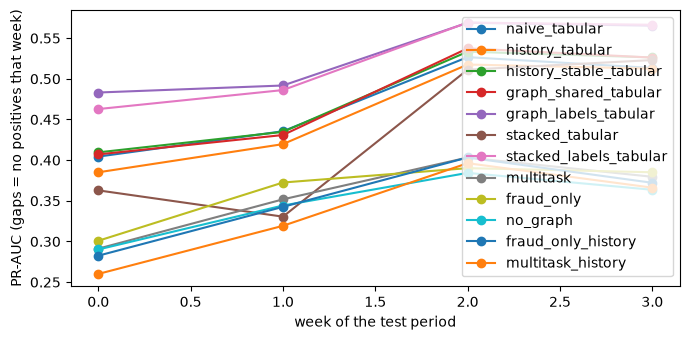

In [7]:
plot_weekly(load_results('results_weekly.csv'));

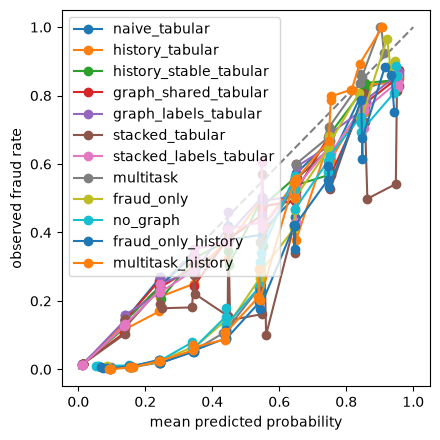

In [8]:
plot_calibration(load_results('calibration.csv'));